In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt



# M2: 1-D Dilated CNN (WaveNet-style)
Deep Learning for Retail Sales Demand Forecasting



In [2]:
print("Loading processed data...")
train_df = pd.read_csv("Data/processed/rossmann_train.csv")
val_df = pd.read_csv("Data/processed/rossmann_validation.csv")

# Sort by Store and Date to ensure correct chronological order
train_df = train_df.sort_values(["Store", "Date"]).reset_index(drop=True)
val_df = val_df.sort_values(["Store", "Date"]).reset_index(drop=True)

print(f"Train shape: {train_df.shape}")
print(f"Validation shape: {val_df.shape}")



Loading processed data...


Train shape: (949194, 10)
Validation shape: (68015, 10)


## 1. Feature Engineering & Scaling
We separate continuous features from categorical features. 
Categorical features will go through Embedding layers; continuous features go directly to the CNN.



In [3]:
# Define features
target_col = "Sales"
cat_cols = ["DayOfWeek", "Promo", "StateHoliday", "SchoolHoliday"] 
cont_cols = ["Customers", "Open"] 

# Encode categorical variables
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    # Fit on both train and val to avoid unknown categories
    all_data = pd.concat([train_df[col], val_df[col]]).astype(str)
    le.fit(all_data)
    train_df[col] = le.transform(train_df[col].astype(str))
    val_df[col] = le.transform(val_df[col].astype(str))
    label_encoders[col] = le

# Scale continuous features and the target
scaler_x = StandardScaler()
train_df[cont_cols] = scaler_x.fit_transform(train_df[cont_cols])
val_df[cont_cols] = scaler_x.transform(val_df[cont_cols])

scaler_y = StandardScaler()
train_df[target_col] = scaler_y.fit_transform(train_df[[target_col]])
val_df[target_col] = scaler_y.transform(val_df[[target_col]])

print("Scaling and encoding completed.")



Scaling and encoding completed.


## 2. PyTorch Dataset & Sequence Generation
We create a sliding window dataset for time-series forecasting.



In [4]:
class RossmannDataset(Dataset):
    def __init__(self, df, seq_length=30):
        self.seq_length = seq_length
        self.samples = []
        
        # We must generate sequences per Store to avoid mixing data between different stores
        for store_id, group in df.groupby("Store"):
            group = group.sort_values("Date")
            
            cats = group[cat_cols].values
            conts = group[cont_cols].values
            targets = group[target_col].values
            
            # Sliding window
            for i in range(len(group) - seq_length):
                x_cat = cats[i : i+seq_length]
                x_cont = conts[i : i+seq_length]
                y = targets[i + seq_length] # Predict the next day
                
                self.samples.append((x_cat, x_cont, y))
                
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        x_cat, x_cont, y = self.samples[idx]
        return (
            torch.tensor(x_cat, dtype=torch.long),
            torch.tensor(x_cont, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32)
        )

SEQ_LENGTH = 30  # Predict based on the last 30 days
BATCH_SIZE = 128

print(f"Generating sliding window sequences (Length={SEQ_LENGTH}). This may take a moment...")
# For speed in testing, you might want to run this on a subset of stores first!
train_dataset = RossmannDataset(train_df, seq_length=SEQ_LENGTH)
val_dataset = RossmannDataset(val_df, seq_length=SEQ_LENGTH)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f"Total training sequences: {len(train_dataset)}")
print(f"Total validation sequences: {len(val_dataset)}")



Generating sliding window sequences (Length=30). This may take a moment...


Total training sequences: 915744
Total validation sequences: 34565


## 3. WaveNet-Style 1D Dilated CNN
The model uses dilated convolutions to build a large receptive field, capturing both local and seasonal patterns.



In [5]:
class DilatedCNNForecaster(nn.Module):
    def __init__(self, cat_cardinalities, cont_dim, embedding_dim=4, channels=32):
        super().__init__()
        
        # Categorical Embeddings
        self.embeddings = nn.ModuleList([
            nn.Embedding(num_classes, embedding_dim) for num_classes in cat_cardinalities
        ])
        
        # Input dimension = sum of embedding dims + number of continuous features
        cnn_in_dim = (len(cat_cardinalities) * embedding_dim) + cont_dim
        
        # Dilated Convolutional Blocks (WaveNet style)
        self.conv1 = nn.Conv1d(cnn_in_dim, channels, kernel_size=2, dilation=1)
        self.conv2 = nn.Conv1d(channels, channels, kernel_size=2, dilation=2)
        self.conv3 = nn.Conv1d(channels, channels, kernel_size=2, dilation=4)
        self.conv4 = nn.Conv1d(channels, channels, kernel_size=2, dilation=8)
        
        # Final fully connected layers
        self.fc1 = nn.Linear(channels, 16)
        self.fc2 = nn.Linear(16, 1)
        
    def forward(self, x_cat, x_cont):
        # x_cat shape: (Batch, Seq, Num_Cats)
        # x_cont shape: (Batch, Seq, Num_Conts)
        
        # 1. Embed categorical variables
        embedded = []
        for i, emb_layer in enumerate(self.embeddings):
            embedded.append(emb_layer(x_cat[:, :, i]))
        
        # Concatenate embeddings and continuous features
        # Shape: (Batch, Seq, Total_Features)
        x = torch.cat(embedded + [x_cont], dim=-1)
        
        # PyTorch Conv1d expects shape: (Batch, Channels, Seq)
        x = x.transpose(1, 2)
        
        # 2. Pass through Dilated Convolutions
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        
        # 3. Global Average Pooling (average across the time dimension)
        # Shape becomes (Batch, Channels)
        x = torch.mean(x, dim=2)
        
        # 4. Fully Connected Output
        x = F.relu(self.fc1(x))
        out = self.fc2(x)
        return out.squeeze()

# Cardinalities for embeddings
cat_cards = [len(le.classes_) for le in label_encoders.values()]
model = DilatedCNNForecaster(cat_cardinalities=cat_cards, cont_dim=len(cont_cols))
print(model)



DilatedCNNForecaster(
  (embeddings): ModuleList(
    (0): Embedding(7, 4)
    (1): Embedding(2, 4)
    (2): Embedding(4, 4)
    (3): Embedding(2, 4)
  )
  (conv1): Conv1d(18, 32, kernel_size=(2,), stride=(1,))
  (conv2): Conv1d(32, 32, kernel_size=(2,), stride=(1,), dilation=(2,))
  (conv3): Conv1d(32, 32, kernel_size=(2,), stride=(1,), dilation=(4,))
  (conv4): Conv1d(32, 32, kernel_size=(2,), stride=(1,), dilation=(8,))
  (fc1): Linear(in_features=32, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=1, bias=True)
)


## 4. Training Setup


In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# MSE Loss since target is continuous (Sales)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(f"Model ready to train on {device}!")

# Quick test batch
for x_c, x_co, y in train_loader:
    out = model(x_c.to(device), x_co.to(device))
    print(f"Sample Output shape: {out.shape}, Target shape: {y.shape}")
    break


Model ready to train on cpu!
Sample Output shape: torch.Size([128]), Target shape: torch.Size([128])


## 5. Training Loop
This cell runs the actual training process. It iterates over the data in `EPOCHS`. 

*(Note: Since this dataset has ~1 million rows, an epoch contains thousands of batches. We'll run it for 2 epochs for demonstration. You can increase it later to improve accuracy!)*

Starting Training...


Epoch 1 - Batch 1000/7154 - Loss: 0.2861


Epoch 1 - Batch 2000/7154 - Loss: 0.2191


Epoch 1 - Batch 3000/7154 - Loss: 0.3751


Epoch 1 - Batch 4000/7154 - Loss: 0.3629


...

Epoch 2 - Batch 4000/7154 - Loss: 0.2529


Epoch 2 - Batch 5000/7154 - Loss: 0.2069


Epoch 2 - Batch 6000/7154 - Loss: 0.3369


Epoch 2 - Batch 7000/7154 - Loss: 0.3302



--- Epoch 2/2 Summary ---
Train Loss: 0.2686 | Val Loss: 0.2175

Training Complete!


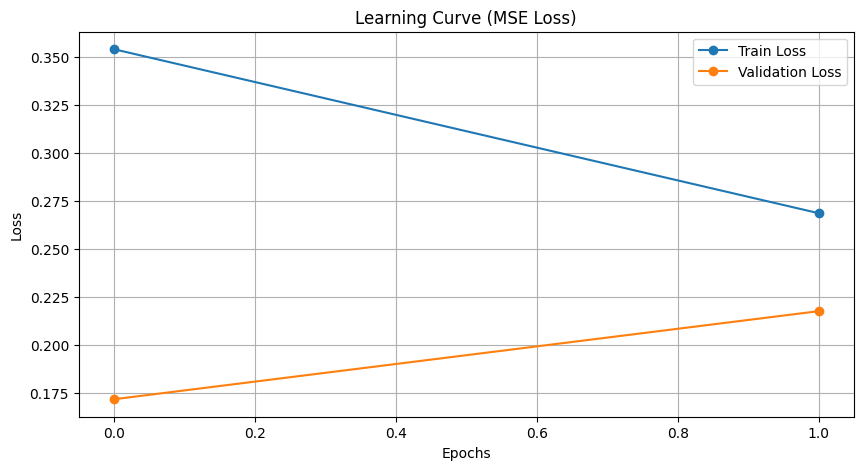

In [7]:
EPOCHS = 2
train_losses = []
val_losses = []

print("Starting Training...")
for epoch in range(EPOCHS):
    model.train()
    epoch_train_loss = 0
    
    for batch_idx, (x_cat, x_cont, y) in enumerate(train_loader):
        x_cat, x_cont, y = x_cat.to(device), x_cont.to(device), y.to(device)
        
        optimizer.zero_grad()
        predictions = model(x_cat, x_cont)
        loss = criterion(predictions, y)
        loss.backward()
        optimizer.step()
        
        epoch_train_loss += loss.item()
        
        # Print progress every 1000 batches so we know it hasn't frozen
        if (batch_idx + 1) % 1000 == 0:
            print(f"Epoch {epoch+1} - Batch {batch_idx+1}/{len(train_loader)} - Loss: {loss.item():.4f}")
            
    avg_train_loss = epoch_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    # Validation phase
    model.eval()
    epoch_val_loss = 0
    with torch.no_grad():
        for x_cat, x_cont, y in val_loader:
            x_cat, x_cont, y = x_cat.to(device), x_cont.to(device), y.to(device)
            predictions = model(x_cat, x_cont)
            loss = criterion(predictions, y)
            epoch_val_loss += loss.item()
            
    avg_val_loss = epoch_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    
    print(f"\n--- Epoch {epoch+1}/{EPOCHS} Summary ---")
    print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}\n")

print("Training Complete!")

# Plotting the learning curve
plt.figure(figsize=(10, 5))
plt.plot(train_losses, marker='o', label='Train Loss')
plt.plot(val_losses, marker='o', label='Validation Loss')
plt.title('Learning Curve (MSE Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


## 6. Preliminary Validation Results
Here we inverse-transform our scaled predictions back into actual sales dollars to calculate the exact RMSE, MAE, and RMSPE metrics (just like the LSTM baseline).

In [ ]:
model.eval()
all_predictions = []
all_targets = []

print("Running validation set for final metrics...")
with torch.no_grad():
    for x_cat, x_cont, y in val_loader:
        x_cat, x_cont = x_cat.to(device), x_cont.to(device)
        predictions = model(x_cat, x_cont).cpu().numpy()
        all_predictions.append(predictions)
        all_targets.append(y.numpy())

# Flatten arrays
pred_scaled = np.concatenate(all_predictions).reshape(-1, 1)
true_scaled = np.concatenate(all_targets).reshape(-1, 1)

# Inverse transform back to real sales numbers
pred_sales = scaler_y.inverse_transform(pred_scaled).flatten()
true_sales = scaler_y.inverse_transform(true_scaled).flatten()

# A neural network might predict negative sales; we cap it at 0
pred_sales = np.maximum(pred_sales, 0)

# Calculate Metrics
rmse = np.sqrt(np.mean((true_sales - pred_sales) ** 2))
mae = np.mean(np.abs(true_sales - pred_sales))

# RMSPE (only calculated where true_sales > 0 to avoid division by zero)
nonzero = true_sales > 0
rmspe = np.sqrt(np.mean( ((true_sales[nonzero] - pred_sales[nonzero]) / true_sales[nonzero]) ** 2 )) * 100

print("\nM2 1-D Dilated CNN — Preliminary Result")
print("-" * 55)
print(f"RMSE : {rmse:,.2f}")
print(f"MAE  : {mae:,.2f}")
print(f"RMSPE: {rmspe:.2f}%")
print(f"Validation samples: {len(true_sales):,}")
